# 1. What is Boosting in Machine Learning? Explain how it improves weak learners?

- Boosting is an ensemble learning technique that combines multiple weak learners to create a stronger and more accurate model.

A weak learner is a model that performs only slightly better than random guessing. In boosting, these weak learners are trained sequentially, meaning each new learner focuses on correcting the errors made by the previous learners.

For example, in AdaBoost, more importance is given to incorrectly classified data points so that the next model focuses more on those difficult cases. The predictions of all the learners are then combined, usually with different weights, to produce the final prediction.

# How Boosting Improves Weak Learners
Train a weak learner on the training data.

Identify the observations that were predicted incorrectly.

Give greater importance to these difficult observations.

Train the next weak learner to focus on these errors.

Repeat the process for several learners.

Combine all learners to create a stronger final model.


# 2. What is the difference between AdaBoost and Gradient Boosting in terms of how models are trained?

- Difference Between AdaBoost and Gradient Boosting

Both methods train weak learners sequentially, but they improve the models in different ways.

 AdaBoost:

AdaBoost gives more weight to incorrectly classified data points after each round. The next weak learner focuses more on these difficult examples. The final prediction combines the learners using weighted voting.

 Gradient Boosting:

Gradient Boosting trains each new model to correct the errors (residuals) of the current combined model. It uses a loss function and gradient descent to determine how the next learner should improve the predictions.

In simple words:

 AdaBoost: Focuses on misclassified observations by changing their weights.

 Gradient Boosting: Focuses on reducing prediction errors by fitting new models to the residuals/gradients.

Key difference: AdaBoost changes the importance of training examples, while Gradient Boosting changes the direction of the next model using the loss function's gradient.

# 3.  How does regularization help in XGBoost?

- Regularization in XGBoost helps prevent overfitting by controlling the complexity of the decision trees and the overall model.

It works mainly in two ways:

 L1 Regularization (reg_alpha)

Penalizes large leaf weights.

Can make some weights zero, effectively reducing the influence of less useful features.
L2 Regularization (reg_lambda)

Penalizes large leaf weights.

Helps keep the model simpler and more stable.

XGBoost also controls tree complexity using parameters such as max_depth, min_child_weight, and gamma.


# 4. Why is CatBoost considered efficient for handling categorical data?

- CatBoost is designed to handle categorical features directly, so they usually do not need to be manually converted using techniques such as one-hot encoding.

 Its key advantages are:

Native categorical feature handling – CatBoost automatically processes categorical variables such as gender, city, or product type.

Target-based encoding – It uses statistical information from the target variable to represent categories in a useful way.

Ordered Target Statistics – CatBoost uses an ordered approach to reduce target leakage and overfitting during categorical feature encoding.

Less preprocessing – Since categorical variables can be provided directly, the data preparation process is often simpler.


# 5. What are some real-world applications where boosting techniques are preferred over bagging methods?

- Real-World Applications Where Boosting Is Preferred Over Bagging

Boosting techniques are often useful when the goal is to achieve high predictive accuracy and capture complex patterns in the data.

Some common applications include:

1. Credit Risk and Loan Default Prediction

Boosting can identify complex relationships between customer financial information and the likelihood of default.

2. Fraud Detection

Techniques such as XGBoost can identify subtle patterns associated with fraudulent transactions.

3. Customer Churn Prediction

Boosting can help predict which customers are likely to stop using a service based on their behavior and history.

4. Medical Diagnosis

Boosting can combine many weak learners to improve classification of diseases based on patient information.

5. Search Ranking and Recommendation Systems

Gradient boosting methods can be used to rank search results or recommend products based on user behavior.

6. Sales and Demand Prediction

Boosting can model complex relationships between factors such as price, seasonality, promotions, and customer behavior.




In [2]:
### 6. Write a Python program to:
###● Train an AdaBoost Classifier on the Breast Cancer dataset

###● Print the model accuracy

###● Use sklearn.datasets.load_breast_cancer() for classification tasks.

###● Use sklearn.datasets.fetch_california_housing() for regression tasks.

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score

# Load the Breast Cancer dataset
data = load_breast_cancer()

X = data.data
y = data.target

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create and train the AdaBoost Classifier
model = AdaBoostClassifier(
    n_estimators=50,
    random_state=42
)

model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

# Print accuracy
print("AdaBoost Classifier Accuracy:", accuracy)

AdaBoost Classifier Accuracy: 0.9649122807017544


In [3]:
### 7. Write a Python program to:
### ● Train a Gradient Boosting Regressor on the California Housing dataset
### ● Evaluate performance using R-squared score

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import r2_score

# Load California Housing dataset
data = fetch_california_housing()

X = data.data
y = data.target

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create Gradient Boosting Regressor
model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Calculate R-squared score
r2 = r2_score(y_test, y_pred)

# Print the result
print("Gradient Boosting Regressor R² Score:", r2)

Gradient Boosting Regressor R² Score: 0.7756446042829697


In [4]:
### 8. Write a Python program to:
### ● Train an XGBoost Classifier on the Breast Cancer dataset
### ● Tune the learning rate using GridSearchCV
### ● Print the best parameters and accuracy

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score
from xgboost import XGBClassifier

# Load Breast Cancer dataset
data = load_breast_cancer()

X = data.data
y = data.target

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create XGBoost Classifier
model = XGBClassifier(
    n_estimators=100,
    random_state=42,
    eval_metric='logloss'
)

# Define parameter grid for learning rate
param_grid = {
    'learning_rate': [0.01, 0.05, 0.1, 0.2]
}

# GridSearchCV
grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy'
)

# Train and tune the model
grid_search.fit(X_train, y_train)

# Print best parameters
print("Best Parameters:", grid_search.best_params_)

# Use the best model for prediction
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Best Parameters: {'learning_rate': 0.2}
Accuracy: 0.956140350877193


Accuracy: 0.9649122807017544


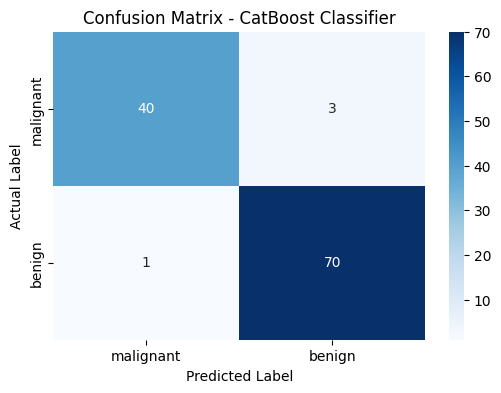

In [12]:
### 9.  Write a Python program to:
### ● Train a CatBoost Classifier
### ● Plot the confusion matrix using seaborn

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score
from catboost import CatBoostClassifier
import seaborn as sns
import matplotlib.pyplot as plt

# Load Breast Cancer dataset
data = load_breast_cancer()

X = data.data
y = data.target

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create CatBoost Classifier
model = CatBoostClassifier(
    iterations=100,
    learning_rate=0.1,
    depth=6,
    verbose=0,
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Print accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

# Plot confusion matrix
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=data.target_names,
    yticklabels=data.target_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - CatBoost Classifier")
plt.show()

# 10. You're working for a FinTech company trying to predict loan default using customer demographics and transaction behavior. The dataset is imbalanced, contains missing values, and has both numeric and categorical features.

 Describe your step-by-step data science pipeline using boosting techniques:

● Data preprocessing & handling missing/categorical values

● Choice between AdaBoost, XGBoost, or CatBoost

● Hyperparameter tuning strategy

● Evaluation metrics you'd choose and why

● How the business would benefit from your model

- Data Science Pipeline for Loan Default Prediction Using Boosting

For a FinTech company, I would build the model in the following steps:

1. Data Preprocessing

a. Understand the data

Identify the target variable, e.g., loan_default (0 = no default, 1 = default).
Examine numeric and categorical features.
Check the percentage of missing values.
Check the class distribution because the dataset is imbalanced.
Remove duplicate records and investigate obvious data errors.

b. Handle missing values

For numeric features, use median imputation because it is less affected by outliers.
For categorical features, use the most frequent category or a separate "Unknown" category.
Avoid using information from the test set when calculating imputation values.

c. Handle categorical features

CatBoost can handle categorical variables directly, so explicit one-hot encoding is often unnecessary.
If using XGBoost or AdaBoost, categorical variables generally need to be encoded, such as with one-hot encoding.

d. Handle class imbalance

Use stratified train/test splitting.
Consider class weights or appropriate sampling techniques.
Do not rely on accuracy alone because a model could achieve high accuracy while performing poorly on default cases.

2. Choosing the Boosting Algorithm

I would consider AdaBoost, XGBoost, and CatBoost.

a. AdaBoost

Simple and effective for many classification problems.

Works by giving greater weight to observations that previous models classified incorrectly.

Can be sensitive to noisy data and outliers.

b. XGBoost

Powerful and highly configurable.

Provides regularization and handles complex nonlinear relationships.

A good choice when the data has been properly encoded and preprocessing is controlled.

c. CatBoost

Particularly useful when the dataset contains many categorical features.

Can process categorical features natively.

Generally reduces the amount of preprocessing required for categorical variables.


For this particular dataset, I would strongly consider CatBoost if there are many categorical customer attributes. XGBoost would also be a strong alternative, especially if the data is mostly numeric or has already been encoded.

3. Train/Test Split

Split the data into training and testing sets, for example:

Training set: 80%

Testing set: 20%

Use stratification so that the proportion of defaulters is approximately preserved in both sets.

In [14]:
### For example:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

4. Hyperparameter Tuning

Use GridSearchCV or RandomizedSearchCV with Stratified K-Fold cross-validation.

Important parameters include:

For XGBoost/CatBoost:

1. n_estimators – number of boosting trees

2. learning_rate – contribution of each tree

3. max_depth – tree complexity

4. subsample – fraction of training samples used

5. min_child_weight / related regularization parameters

6. L1/L2 regularization parameters

In [15]:
### For example:

param_grid = {
    'learning_rate': [0.01, 0.05, 0.1],
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7]
}

### I would use early stopping where supported to prevent unnecessary boosting iterations and reduce overfitting.

5. Evaluation Metrics

Because loan default data is imbalanced, accuracy should not be the primary metric.

I would evaluate using:

Precision – Of customers predicted as defaulters, how many actually default?

Recall – Of all actual defaulters, how many did the model identify?

F1-score – Balances precision and recall.

ROC-AUC – Measures how well the model separates defaulters from non-defaulters across thresholds.

PR-AUC – Particularly useful when the default class is relatively rare.

Confusion Matrix – Shows false positives and false negatives.

For a lending business, I would also examine the cost of false positives versus false negatives. The appropriate classification threshold can then be chosen based on those business costs rather than automatically using 0.5.

6. Model Validation and Interpretation

After selecting the best model:

Evaluate it on the untouched test set.

Examine the confusion matrix and precision/recall.

Check performance across relevant customer groups for potential disparities.
Analyze feature importance.

Use tools such as SHAP when individual prediction explanations are required.

Monitor model performance after deployment because customer behavior and default patterns can change over time.

7. Business Benefits

A well-designed loan-default model could help the FinTech company:

Identify high-risk applicants before approving loans.

Reduce financial losses from defaults.

Improve risk-based lending decisions.

Prioritize manual review for customers requiring additional assessment.

Improve portfolio risk management.

Potentially automate parts of the credit assessment process.

Use predicted risk scores to support decisions about loan amounts or terms.

The model should be used as a decision-support system with appropriate governance, rather than relying solely on an automated prediction for every lending decision.

Overall Pipeline

Raw Customer Data

        ↓

Data Cleaning

        ↓

Missing Value Handling

        ↓

Categorical Feature Handling

        ↓

Class Imbalance Analysis

        ↓

Stratified Train/Test Split

        ↓

Choose Boosting Model


(AdaBoost / XGBoost / CatBoost)

        ↓

Hyperparameter Tuning

        ↓

Cross-Validation

        ↓

Evaluate
(Precision, Recall, F1, ROC-AUC, PR-AUC)

        ↓

Select Operating Threshold

        ↓

Feature/Prediction Interpretation

        ↓

Deployment

        ↓

Continuous Monitoring



In summary: For a dataset containing substantial categorical information and missing values, CatBoost is a particularly natural candidate because it can work directly with categorical features. I would compare it with XGBoost, tune the models using stratified cross-validation, and prioritize precision, recall, F1, and PR-AUC rather than accuracy alone.